In [136]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate as integrate

#importing data for distand supernova
name_dist = np.loadtxt('sn_data(1).txt', max_rows=42, usecols=(0), unpack=True, dtype=str)
redshift_dist, m_effective_dist, m_error_dist = np.loadtxt('sn_data(1).txt', max_rows=42, usecols=(1,2,3), unpack=True)

#importing data for low redshift supernova
name_low = np.loadtxt('sn_data(1).txt', skiprows=47, usecols=(0), unpack=True, dtype=str)
redshift_low, m_effective_low, m_error_low = np.loadtxt('sn_data(1).txt', skiprows=47, usecols=(1,2,3), unpack=True)


In [137]:
#defining constants
H0 = 2.4306e-18 #s^-1
c = 3e10 #cm/s
f_lambda0 = 6.61e-9 #erg/cm^2/s/A

In [138]:
#defining function to calculate d_L
def d_L_low(z):
    return c*z/H0

In [139]:
#defining function to find predicted flux from redshift values
def flux(L, d_L):
    return L/(4*np.pi*d_L**2)

In [140]:
#defining function to find predicted effective magnitude
def m_eff_predicted_low(z, flux):
    return -2.5*np.log10((1+z)*flux/f_lambda0)

In [141]:
#defining chi-squared function
def chi_squared(m_effective_low, m_error_low, m_eff_predicted_low):
    return np.sum(((m_effective_low-m_eff_predicted_low)**2)/(m_error_low**2))

In [142]:
#finding the best value of L by minimising chi-squared
#first need to find a range of trial values for L by using weighted mean

weight = 1/(m_error_low**2)
weighted_mean = np.sum(weight*(m_effective_low + 2.5*np.log10(1 + redshift_low) - 5*np.log10(redshift_low)))/np.sum(weight)
L_weighted_mean = 10**(-0.4*weighted_mean)*4*np.pi*f_lambda0*c**2/H0**2

#trial values between half and double the weighted mean, might need to change this??
trial_L = np.linspace(L_weighted_mean*0.5, L_weighted_mean*2, 4000)

#need a for loop to find chi-squared for each trial value of L 
chi_squared_values = np.zeros(len(trial_L))
for i in range(len(trial_L)):
    chi_squared_values[i] = chi_squared(m_effective_low, m_error_low, m_eff_predicted_low(redshift_low, flux(trial_L[i], d_L_low(redshift_low))))
L_best_fit = trial_L[np.argmin(chi_squared_values)]
#line above finds min value in chi-squared values and assigns the corresponding value of trial Ls to ther best fit for L

#now need to find errors on L best fit value. Use fact we require chi squared to be <=1 for a god fit


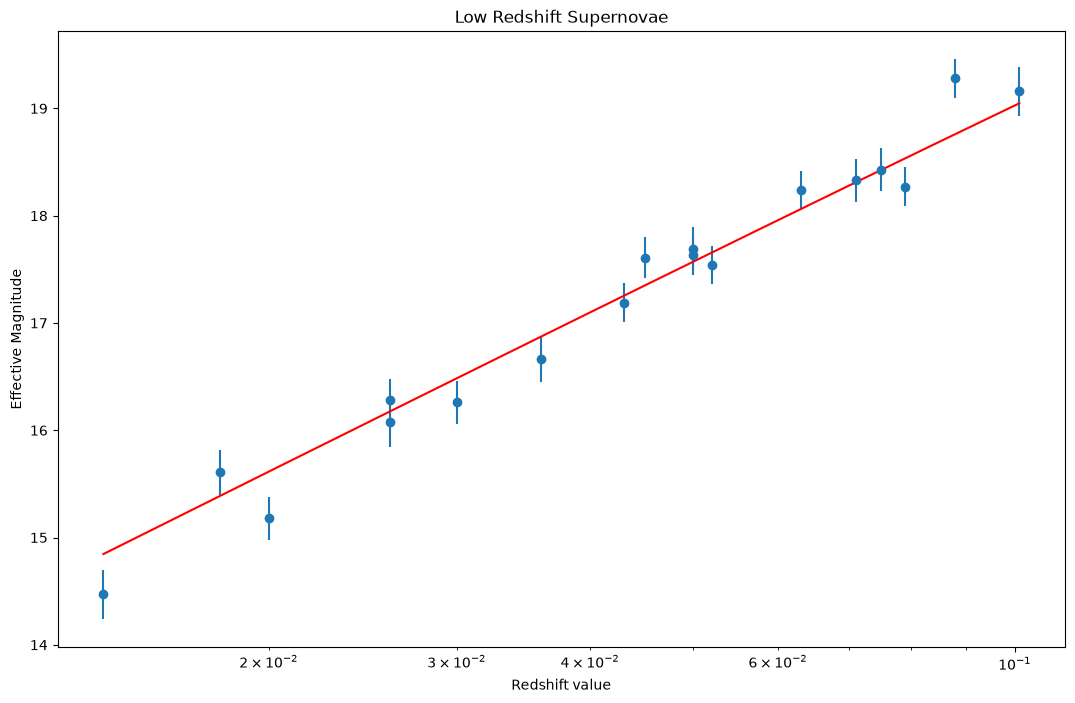

In [143]:
smooth_redshift_low = np.linspace(np.min(redshift_low), np.max(redshift_low), 1000) 
smooth_m_eff_predicted_low = m_eff_predicted_low(smooth_redshift_low, flux(L_best_fit, d_L_low(smooth_redshift_low)))   

plt.figure(figsize=(13,8))
plt.errorbar(redshift_low, m_effective_low, yerr=m_error_low, marker='o', linestyle='none')
plt.plot(smooth_redshift_low, smooth_m_eff_predicted_low, color='red')
plt.xscale('log')
plt.xlabel('Redshift value')
plt.ylabel('Effective Magnitude')
plt.title('Low Redshift Supernovae')
plt.show()

In [144]:
print("Best fit value of L:", L_best_fit)
print("Weighted mean value of L:", L_weighted_mean)

Best fit value of L: 2.8188895121158946e+39
Weighted mean value of L: 2.8188895121158946e+39


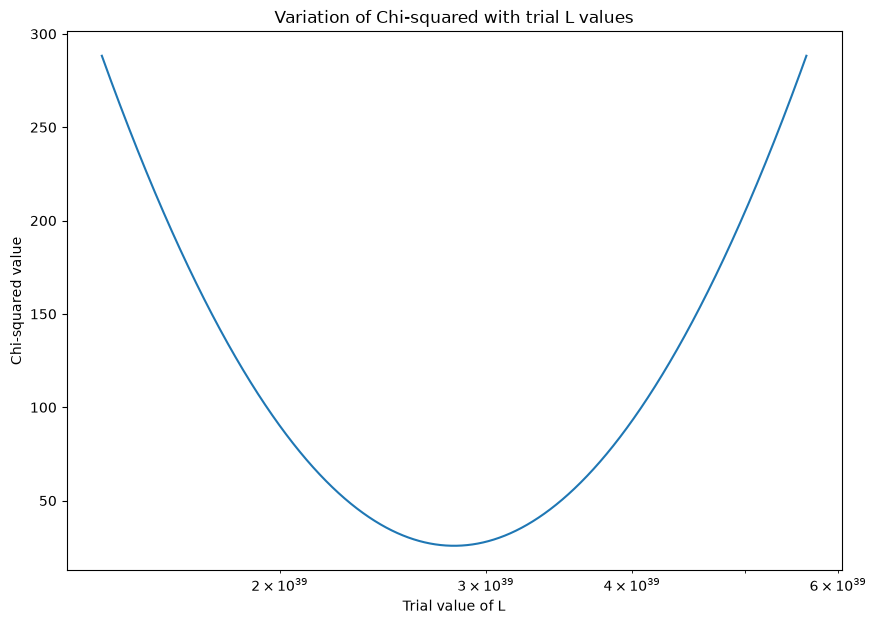

In [145]:
plt.figure(figsize=(10,7))
plt.plot(trial_L, chi_squared_values)
plt.xscale('log')
plt.xlabel('Trial value of L')
plt.ylabel('Chi-squared value')
plt.title('Variation of Chi-squared with trial L values')
plt.show()

In [146]:
#cheching what the chi-squared and reduced chi-squared values are
print("Chi-squared value:",chi_squared_values[np.argmin(chi_squared_values)])
DoF = len(redshift_low)-1
reduced_chi_squared = chi_squared_values/DoF
print("Reduced chi-squared value:", reduced_chi_squared[np.argmin(chi_squared_values)])

Chi-squared value: 25.819180956449664
Reduced chi-squared value: 1.518775350379392


In [147]:
#attempt to find the error on the best fit for L peak
error_range = []
for i in range(len(trial_L)):
    if abs(chi_squared_values[i])-chi_squared_values[np.argmin(chi_squared_values)] <= 1:
        error_range.append(trial_L[i])

max_error = max(error_range)
min_error = min(error_range)

print("Error range for L best fit value: [", min_error, ",", max_error, "]")

Error range for L best fit value: [ 2.7015238947697338e+39 , 2.941541868982153e+39 ]


In [148]:
#define a function to take different trial values of omega and returns d_L
def integrand(z, omega):
    return 1/np.sqrt((1-omega)*(1+z)**3 + omega)

def d_L_dist(z, omega):
    integral = np.array([integrate.quad(lambda z: integrand(z, omega), 0, zi)[0] for zi in z])
    return (c/H0)*(1+z)*integral

In [149]:
omega_trial = np.linspace(0, 1, 1000)
chi_squared_values_omega = np.zeros(len(omega_trial))

for i in range(len(omega_trial)):
    m_eff_predicted_dist = m_eff_predicted_low(redshift_dist, flux(L_best_fit, d_L_dist(redshift_dist, omega_trial[i])))
    chi_squared_values_omega[i] = chi_squared(m_effective_dist, m_error_dist, m_eff_predicted_dist)

omega_best_fit = omega_trial[np.argmin(chi_squared_values_omega)]
print("Best fit value of omega:", omega_best_fit)


Best fit value of omega: 1.0


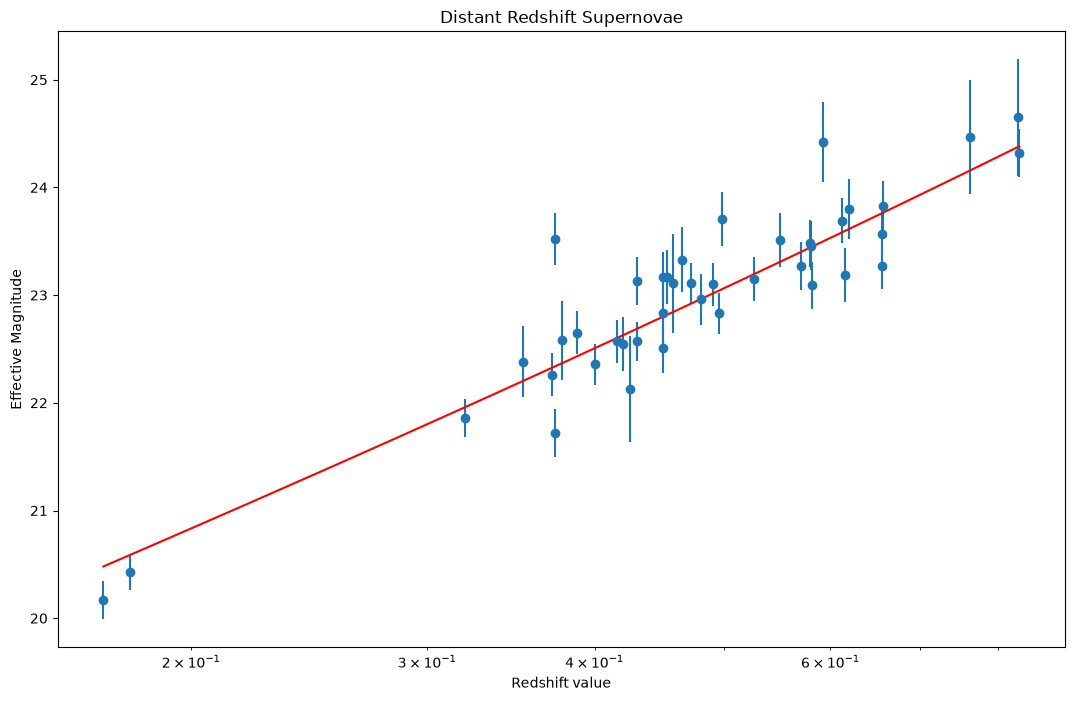

In [150]:
smooth_redshift_dist = np.linspace(np.min(redshift_dist), np.max(redshift_dist), 1000) 
smooth_m_eff_predicted_dist = m_eff_predicted_low(smooth_redshift_dist, flux(L_best_fit, d_L_dist(smooth_redshift_dist, omega_best_fit)))   

plt.figure(figsize=(13,8))
plt.errorbar(redshift_dist, m_effective_dist, yerr=m_error_dist, marker='o', linestyle='none')
plt.plot(smooth_redshift_dist, smooth_m_eff_predicted_dist, color='red')
plt.xscale('log')
plt.xlabel('Redshift value')
plt.ylabel('Effective Magnitude')
plt.title('Distant Redshift Supernovae')
plt.show()

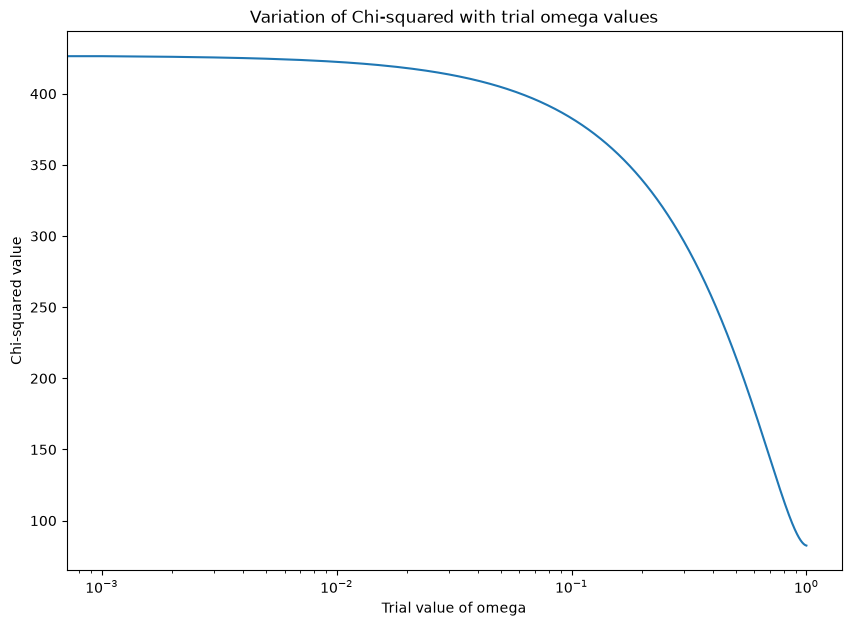

In [151]:
plt.figure(figsize=(10,7))
plt.plot(omega_trial, chi_squared_values_omega)
plt.xscale('log')
plt.xlabel('Trial value of omega')
plt.ylabel('Chi-squared value')
plt.title('Variation of Chi-squared with trial omega values')
plt.show()